# Multi-timeframe trading signals

A small case study. We trade TSLA on hourly bars and use the daily chart as context.
Every strategy is compared with simply buying and holding SPY over the same hours.

The question is simple. Can a few easy rules on the hourly chart do better than holding SPY once fees are paid?

The notebook goes in order. Each step adds one idea on top of the previous one.

## 1. Setup

The settings live in one cell so they are easy to change.
Each trade costs a flat 5 dollars. A reversal from long to short counts as two trades.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.ensemble import HistGradientBoostingClassifier

pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (12, 5)

In [2]:
SYMBOL = "TSLA"
BENCHMARK = "SPY"

CAPITAL = 10_000
FEE = 5.0
BARS_PER_YEAR = 252 * 7   # about 7 hourly bars per trading day
TEST_SHARE = 0.30         # the last 30% of the data is kept for testing

## 2. Download the data

Yahoo Finance only gives about two years of hourly data. That limit shapes the whole study.
We also keep the log return of each bar because log returns add up over time.

The stock and the benchmark are cut to the same hours. That way any difference comes from the strategy and not from the dates.

In [3]:
def download(symbol, interval, period):
    df = yf.Ticker(symbol).history(period=period, interval=interval, auto_adjust=True)
    df = df[["Open", "High", "Low", "Close", "Volume"]].dropna()
    df["ret"] = np.log(df["Close"]).diff()
    return df.dropna()


hourly = download(SYMBOL, "1h", "730d")
daily = download(SYMBOL, "1d", "5y")
bench = download(BENCHMARK, "1h", "730d")

common = hourly.index.intersection(bench.index)
hourly, bench = hourly.loc[common].copy(), bench.loc[common].copy()

print(f"{len(hourly)} hourly bars from {hourly.index[0]:%Y-%m-%d} to {hourly.index[-1]:%Y-%m-%d}")
print(f"{len(daily)} daily bars")

5075 hourly bars from 2023-12-04 to 2026-10-30
1254 daily bars


## 3. Daily context on the hourly chart

The daily chart gives us a simple trend state. If the close is more than 1% above its 20 day average the state is up (+1).
If it is more than 1% below the state is down (-1). Anything in between is neutral (0).

The tricky part is timing. During a trading day we do not know that day's close yet.
So every hourly bar only sees the state from the previous day. That is what the `shift(1)` does.

In [4]:
gap = daily["Close"] / daily["Close"].rolling(20).mean() - 1
daily_state = pd.Series(0, index=daily.index)
daily_state[gap > 0.01] = 1
daily_state[gap < -0.01] = -1

known_state = daily_state.shift(1)
hourly["daily_state"] = known_state.reindex(hourly.index.normalize()).fillna(0).values

hourly["daily_state"].value_counts()

daily_state
 1.0    2363
-1.0    2107
 0.0     605
Name: count, dtype: int64

## 4. Three simple rules

Each rule looks at past prices and gives one answer per bar. +1 means long, -1 means short and 0 means stay out.
They only use prices that already happened, so we can compute them on the whole series at once.

**SMA crossover.** We track two moving averages of the close. The fast one covers 20 bars and the slow one 100 bars.
The fast one reacts quickly and the slow one shows the bigger picture. When the fast one is above the slow one, prices have been rising lately, so we go long.
When it is below we go short. This is trend following. It does well in long clean trends and bleeds a little when the price goes sideways.

**Momentum.** We compare the price now with the price 60 bars ago. If it went up we go long. If it went down we go short.
The idea is that things moving up tend to keep moving up for a while. It is also trend following, just more direct.
It flips side more often than the crossover, so it pays more fees.

**Mean reversion.** This is the opposite bet. When the price runs too far from its 20 bar average we expect it to come back.
More than 1% above the average means short. More than 1% below means long. Close to the average we stay out.
It works when the price bounces inside a range. It hurts in a strong trend because it keeps fighting it.

In [5]:
def sma_cross(df, fast=20, slow=100):
    diff = df["Close"].rolling(fast).mean() - df["Close"].rolling(slow).mean()
    return np.sign(diff).fillna(0)


def momentum(df, lookback=60):
    return np.sign(df["Close"].pct_change(lookback)).fillna(0)


def mean_reversion(df, period=20, threshold=0.01):
    gap = df["Close"] / df["Close"].rolling(period).mean() - 1
    signal = pd.Series(0.0, index=df.index)
    signal[gap < -threshold] = 1
    signal[gap > threshold] = -1
    return signal


RULES = {"SMA cross": sma_cross, "Momentum": momentum, "Mean reversion": mean_reversion}

## 5. The backtest

A backtest is a replay. We take old prices and pretend we traded them bar by bar with our rule.
At each bar we only know what happened up to that moment. At the end we get an equity curve, which is how the account would have moved.

The goal is not to find a money machine. It is to check if a rule has any real edge after fees, and if it beats just holding SPY.
A backtest is only honest if it never peeks at the future. So a signal seen at the close of bar `t` is traded on bar `t+1`. The `shift(1)` in the code takes care of that.

The account starts with 10,000 dollars. Each bar the equity grows with the position times the return. Then the fees for that bar are paid in cash.

In [6]:
def backtest(signal, df):
    position = signal.shift(1).fillna(0)
    changed = position.diff().fillna(position) != 0
    reversed_ = position * position.shift(1).fillna(0) < 0
    trades = changed.astype(int) + reversed_.astype(int)

    growth = np.exp(position.values * df["ret"].values)
    equity = np.empty(len(df))
    value = CAPITAL
    for i in range(len(df)):
        value = max(value * growth[i] - FEE * trades.iloc[i], 1.0)
        equity[i] = value
    return pd.DataFrame({"position": position, "trades": trades, "equity": equity}, index=df.index)


def stats(bt):
    eq = bt["equity"]
    ret = np.log(eq / eq.shift(1).fillna(CAPITAL))
    return {
        "total return": eq.iloc[-1] / CAPITAL - 1,
        "volatility": ret.std() * np.sqrt(BARS_PER_YEAR),
        "sharpe": ret.mean() / ret.std() * np.sqrt(BARS_PER_YEAR),
        "max drawdown": (eq / eq.cummax() - 1).min(),
        "trades": int(bt["trades"].sum()),
        "fees": bt["trades"].sum() * FEE,
        "time in market": (bt["position"] != 0).mean(),
    }

Here is each rule over the full history with its default settings.
It is only a first look. The fair comparison comes later on data the rules have never seen.

A few columns to know. The Sharpe ratio is the return divided by how much the equity shakes, per year. Higher is better and above 1 is good.
Max drawdown is the worst drop from a previous high. It is the pain you would have had to sit through.

In [7]:
first_look = {name: stats(backtest(rule(hourly), hourly)) for name, rule in RULES.items()}
pd.DataFrame(first_look).T.round(3)

,total return,volatility,sharpe,max drawdown,trades,fees,time in market
SMA cross,1.094,0.560,0.459,-0.452,125.0,625.0,0.980
Momentum,0.921,0.561,0.405,-0.621,495.0,2475.0,0.988
Mean reversion,-0.457,0.463,-0.458,-0.673,937.0,4685.0,0.702


## 6. Train and test

We split the data in two. The first 70% is used to pick the settings of each rule. The last 30% is only used to score them.

For every rule we try a few settings on the train part and keep the one with the best Sharpe.
Then we check how that choice does on the test part next to the default setting.
If the chosen one does worse than the default it means the search was mostly fitting noise.

In [8]:
split = int(len(hourly) * (1 - TEST_SHARE))
train, test = hourly.iloc[:split], hourly.iloc[split:]

GRID = {
    "SMA cross": [dict(fast=10, slow=50), dict(fast=20, slow=100), dict(fast=50, slow=200)],
    "Momentum": [dict(lookback=20), dict(lookback=60), dict(lookback=120)],
    "Mean reversion": [dict(period=20, threshold=0.01), dict(period=20, threshold=0.02),
                       dict(period=50, threshold=0.02)],
}


def score(rule, params, part):
    signal = rule(hourly, **params).loc[part.index]
    return stats(backtest(signal, part))["sharpe"]


rows = []
for name, rule in RULES.items():
    train_scores = [score(rule, p, train) for p in GRID[name]]
    best = GRID[name][int(np.argmax(train_scores))]
    rows.append({"rule": name, "chosen": best, "train sharpe": max(train_scores),
                 "test sharpe (chosen)": score(rule, best, test),
                 "test sharpe (default)": score(rule, {}, test)})

pd.DataFrame(rows).set_index("rule").round(3)

,chosen,train sharpe,test sharpe (chosen),test sharpe (default)
rule,,,,
SMA cross,"{'fast': 20, 'slow': 100}",0.690,-0.274,-0.274
Momentum,{'lookback': 60},1.168,-2.257,-2.257
Mean reversion,"{'period': 20, 'threshold': 0.02}",0.506,0.611,0.292


## 7. Does the daily trend help?

First a simple question. Are the hourly signals better when the daily trend agrees with them?
For every bar we look at the return of the next hour in the direction of the signal.
Then we split the bars into agreeing and opposing with the daily state.

In [9]:
next_ret = hourly["ret"].shift(-1)
rows = []
for name, rule in RULES.items():
    signal = rule(hourly)
    active = signal != 0
    agree = active & (signal == hourly["daily_state"])
    oppose = active & (signal == -hourly["daily_state"])
    edge = signal * next_ret * 10_000   # in basis points
    rows.append({"rule": name, "agree (bps)": edge[agree].mean(),
                 "oppose (bps)": edge[oppose].mean(),
                 "bars agree": int(agree.sum()), "bars oppose": int(oppose.sum())})

pd.DataFrame(rows).set_index("rule").round(3)

,agree (bps),oppose (bps),bars agree,bars oppose
rule,,,,
SMA cross,0.862,6.828,4111,281
Momentum,0.798,1.897,3736,692
Mean reversion,2.046,0.810,1246,1915


Now we use the daily state as a filter. A long signal is dropped when the daily trend is down. A short signal is dropped when it is up.
A neutral day lets every signal through. The scores are on the test part only.

In [10]:
def daily_filter(signal, state):
    return signal.where(signal * state >= 0, 0)


rows = []
for name, rule in RULES.items():
    signal = rule(hourly).loc[test.index]
    filtered = daily_filter(signal, test["daily_state"])
    rows.append({"rule": name,
                 "sharpe plain": stats(backtest(signal, test))["sharpe"],
                 "sharpe filtered": stats(backtest(filtered, test))["sharpe"]})

pd.DataFrame(rows).set_index("rule").round(3)

,sharpe plain,sharpe filtered
rule,,
SMA cross,-0.274,-0.384
Momentum,-2.257,-1.347
Mean reversion,0.292,-0.314


## 8. Position sizing by volatility

Instead of always holding a full position we can hold less when the market is wild.
The size is the target volatility of 30% divided by the recent volatility, capped at 1.

With a flat fee every size change costs money. So the size moves in steps of 0.25 and only changes when it really needs to.

In [11]:
def vol_target(signal, df, target=0.30, lookback=100):
    vol = df["ret"].rolling(lookback).std() * np.sqrt(BARS_PER_YEAR)
    size = (target / vol).clip(upper=1.0)
    size = ((size * 4).round() / 4).clip(lower=0.25)
    return signal * size.fillna(0)


rows = []
for name, rule in RULES.items():
    signal = rule(hourly)
    sized = vol_target(signal, hourly).loc[test.index]
    plain = stats(backtest(signal.loc[test.index], test))
    managed = stats(backtest(sized, test))
    rows.append({"rule": name, "sharpe plain": plain["sharpe"], "sharpe sized": managed["sharpe"],
                 "drawdown plain": plain["max drawdown"], "drawdown sized": managed["max drawdown"],
                 "trades sized": managed["trades"]})

pd.DataFrame(rows).set_index("rule").round(3)

,sharpe plain,sharpe sized,drawdown plain,drawdown sized,trades sized
rule,,,,,
SMA cross,-0.274,-0.497,-0.301,-0.272,72
Momentum,-2.257,-2.341,-0.631,-0.532,224
Mean reversion,0.292,-0.100,-0.310,-0.259,269


## 9. A small machine learning model

The model gets a few features built from past prices plus the daily state.
It tries to predict if the price will be higher 20 hours later.

There is one trap here. The last 20 labels of the train part look into the test part. So we drop them before training.
The model goes long when it is fairly sure the price goes up and short when it is fairly sure it goes down. Otherwise it stays flat.

In [12]:
HORIZON = 20


def make_features(df):
    f = pd.DataFrame(index=df.index)
    for n in (1, 5, 20, 60):
        f[f"ret_{n}"] = np.log(df["Close"]).diff(n)
    f["dist_sma20"] = df["Close"] / df["Close"].rolling(20).mean() - 1
    f["dist_sma100"] = df["Close"] / df["Close"].rolling(100).mean() - 1
    f["vol_20"] = df["ret"].rolling(20).std()
    f["hour"] = df.index.hour
    f["daily_state"] = df["daily_state"]
    return f


X = make_features(hourly)
future = np.log(hourly["Close"]).shift(-HORIZON) - np.log(hourly["Close"])
y = (future > 0).astype(int)

X_train = X.loc[train.index[:-HORIZON]].dropna()
y_train = y.loc[X_train.index]

model = HistGradientBoostingClassifier(max_depth=3, max_iter=200, learning_rate=0.05)
model.fit(X_train, y_train)

prob = pd.Series(model.predict_proba(X.loc[test.index])[:, 1], index=test.index)
ml_signal = pd.Series(0.0, index=test.index)
ml_signal[prob > 0.55] = 1
ml_signal[prob < 0.45] = -1

known = future.loc[test.index].notna()
accuracy = ((prob > 0.5) == y.loc[test.index])[known].mean()
print(f"test accuracy {accuracy:.3f}  share of bars going up {y.loc[test.index][known].mean():.3f}")

test accuracy 0.448  share of bars going up 0.477


Accuracy alone can fool you. If the price went up 55% of the time, always saying up already gives 55%.
Compare the accuracy with the share of bars that went up.

## 10. Everything against the benchmark

All results below cover the same test hours. SPY buy and hold is the bar to beat.
Look at the Sharpe ratio before the total return. A strategy that makes more money with much more risk has not really won.

In [13]:
results = {
    f"{BENCHMARK} buy & hold": backtest(pd.Series(1.0, index=test.index), bench.loc[test.index]),
    f"{SYMBOL} buy & hold": backtest(pd.Series(1.0, index=test.index), test),
}
for name, rule in RULES.items():
    results[name] = backtest(rule(hourly).loc[test.index], test)
results["SMA cross + daily filter"] = backtest(
    daily_filter(sma_cross(hourly).loc[test.index], test["daily_state"]), test)
results["SMA cross + vol sizing"] = backtest(vol_target(sma_cross(hourly), hourly).loc[test.index], test)
results["ML model"] = backtest(ml_signal, test)

table = pd.DataFrame({name: stats(bt) for name, bt in results.items()}).T
table.round(3)

,total return,volatility,sharpe,max drawdown,trades,fees,time in market
SPY buy & hold,0.118,0.130,0.994,-0.096,1.0,5.0,0.999
TSLA buy & hold,-0.159,0.448,-0.448,-0.395,1.0,5.0,0.999
SMA cross,-0.100,0.448,-0.274,-0.301,41.0,205.0,0.999
Momentum,-0.582,0.448,-2.257,-0.631,197.0,985.0,0.999
Mean reversion,0.091,0.347,0.292,-0.310,257.0,1285.0,0.671
SMA cross + daily filter,-0.136,0.442,-0.384,-0.321,45.0,225.0,0.934
SMA cross + vol sizing,-0.135,0.336,-0.497,-0.272,72.0,360.0,0.999
ML model,-0.379,0.365,-1.514,-0.546,531.0,2655.0,0.678


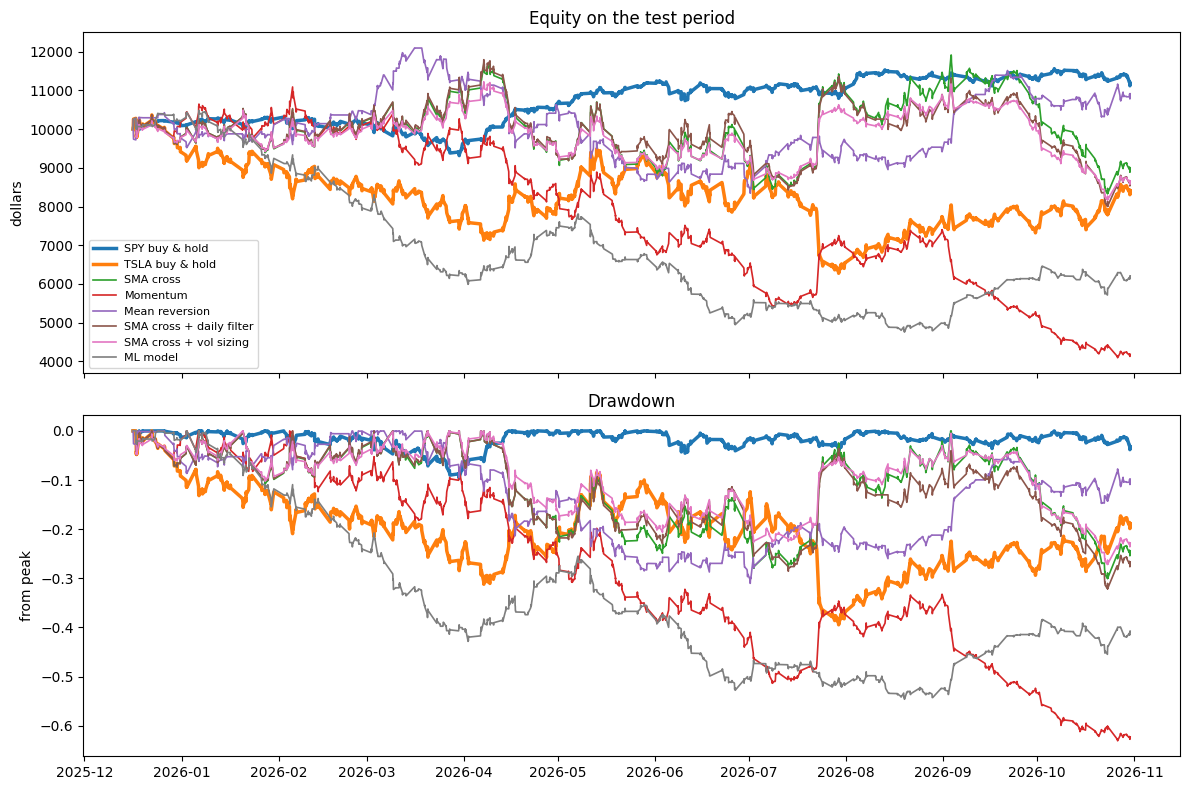

In [14]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for name, bt in results.items():
    width = 2.5 if "buy & hold" in name else 1.2
    ax1.plot(bt.index, bt["equity"], label=name, linewidth=width)
    ax2.plot(bt.index, bt["equity"] / bt["equity"].cummax() - 1, linewidth=width)

ax1.set_title("Equity on the test period")
ax1.set_ylabel("dollars")
ax1.legend(fontsize=8)
ax2.set_title("Drawdown")
ax2.set_ylabel("from peak")
plt.tight_layout()
plt.show()

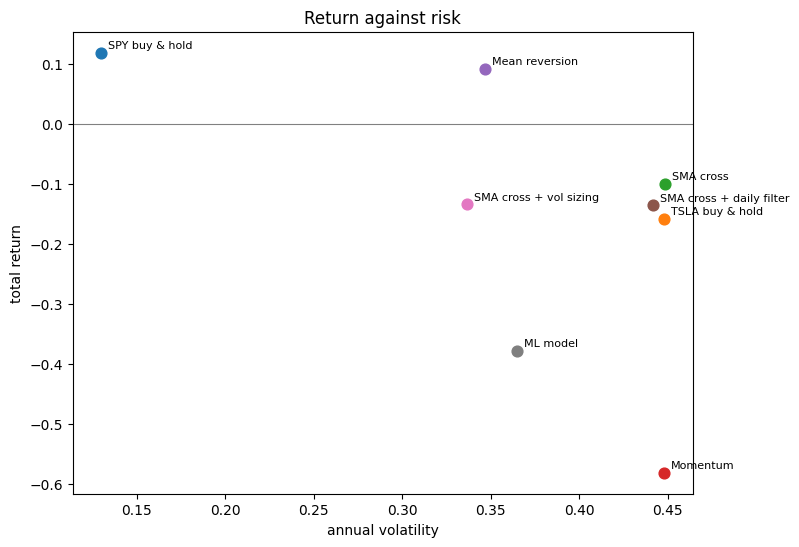

In [15]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, row in table.iterrows():
    ax.scatter(row["volatility"], row["total return"], s=60)
    ax.annotate(name, (row["volatility"], row["total return"]), fontsize=8,
                xytext=(5, 3), textcoords="offset points")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("annual volatility")
ax.set_ylabel("total return")
ax.set_title("Return against risk")
plt.show()

## 11. What to take from this

Two years of hourly data is not much. A good Sharpe on the test part can still be luck.
The more rules and settings you try, the more likely one of them looks good by chance.

The ideas worth keeping are the habits. Never use a bar before it is closed. Keep a test period you do not touch.
Count the fees. Always compare with a simple benchmark on the same dates.

Good next steps are trying other symbols or a longer daily history. You can also add your own rule in step 4 and run the rest again.